In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [43]:
df = pd.read_csv(r"results\experiment_results.csv")
df.head(5)

,market,universe_label,universe_size,B,q,lambda_alpha,lambda_value,lookback,backtest_days,constraint_active,...,std_energy,sa_violation_rate,asset_consistency,expected_return,volatility,sharpe_ratio,diversification_ratio,max_drawdown,total_return,ann_return
0,india,u10,10,1,0.1,1.0,0.266101,126,126,True,...,0.000000e+00,1.0,1.0,0.573264,0.255517,2.243543,1.0,-0.056677,0.092564,0.193118
1,india,u10,10,1,0.1,1.0,0.230835,252,126,True,...,0.000000e+00,1.0,1.0,0.452178,0.279650,1.616944,1.0,-0.181584,-0.063428,-0.122518
2,india,u10,10,1,0.1,1.0,0.128870,504,126,False,...,0.000000e+00,1.0,1.0,0.375347,0.255123,1.471241,1.0,-0.181584,-0.063428,-0.122518
3,india,u10,10,1,0.1,3.0,0.798302,126,126,True,...,0.000000e+00,0.0,1.0,0.573264,0.255517,2.243543,1.0,-0.056677,0.092564,0.193118
4,india,u10,10,1,0.1,3.0,0.692504,252,126,True,...,2.220446e-16,0.0,1.0,0.452178,0.279650,1.616944,1.0,-0.181584,-0.063428,-0.122518


In [44]:
df.describe()

,universe_size,B,q,lambda_alpha,lambda_value,lookback,backtest_days,energy_B,energy_B_plus2,num_selected,...,std_energy,sa_violation_rate,asset_consistency,expected_return,volatility,sharpe_ratio,diversification_ratio,max_drawdown,total_return,ann_return
count,2025.000000,2025.000000,2025.000000,2025.000000,2025.000000,2025.000000,2025.0,2025.000000,2025.000000,2025.000000,...,2025.000000,2025.000000,2025.000000,2025.000000,2025.000000,2025.000000,2025.000000,2025.000000,2025.000000,2025.000000
mean,30.000000,6.000000,0.533333,3.000000,0.966749,294.000000,126.0,-49.929212,-45.130265,5.919506,...,0.024019,0.164938,0.981065,0.393670,0.248920,1.837508,1.440655,-0.148691,0.105180,9.002041
std,14.145629,3.916747,0.368270,1.633397,0.757673,157.188427,0.0,89.378913,87.714898,3.861094,...,0.045621,0.362489,0.029317,0.226453,0.170248,0.809298,0.237048,0.152941,0.910816,106.036818
min,10.000000,1.000000,0.100000,1.000000,0.128870,126.000000,126.0,-1047.810019,-1027.013338,1.000000,...,0.000000,0.000000,0.840000,-0.031261,0.103578,-0.046195,1.000000,-0.632977,-0.597763,-0.930002
25%,20.000000,3.000000,0.100000,1.000000,0.365210,126.000000,126.0,-54.196181,-48.838113,3.000000,...,0.000000,0.000000,0.966667,0.257124,0.150501,1.223902,1.275429,-0.166026,-0.024525,-0.048670
50%,30.000000,5.000000,0.500000,3.000000,0.788810,252.000000,126.0,-16.977981,-12.793401,5.000000,...,0.000000,0.000000,1.000000,0.345285,0.179814,1.799459,1.432016,-0.077893,0.036948,0.075909
75%,40.000000,9.000000,1.000000,5.000000,1.286926,504.000000,126.0,-4.859574,-1.187613,9.000000,...,0.033858,0.000000,1.000000,0.454039,0.272869,2.369790,1.605603,-0.053851,0.162555,0.343896
max,50.000000,15.000000,1.000000,5.000000,4.679589,504.000000,126.0,1.698443,16.126673,17.000000,...,0.475022,1.000000,1.000000,1.923578,0.991376,4.111333,2.016816,-0.020720,10.971772,1405.768339


In [45]:
df.isnull().sum()

market                   0
universe_label           0
universe_size            0
B                        0
q                        0
lambda_alpha             0
lambda_value             0
lookback                 0
backtest_days            0
constraint_active        0
energy_B                 0
energy_B_plus2           0
selected_assets          0
num_selected             0
violation                0
violation_mag            0
mean_energy              0
std_energy               0
sa_violation_rate        0
asset_consistency        0
expected_return          0
volatility               0
sharpe_ratio             0
diversification_ratio    0
max_drawdown             0
total_return             0
ann_return               0
dtype: int64

In [46]:
df.dropna(inplace=True)

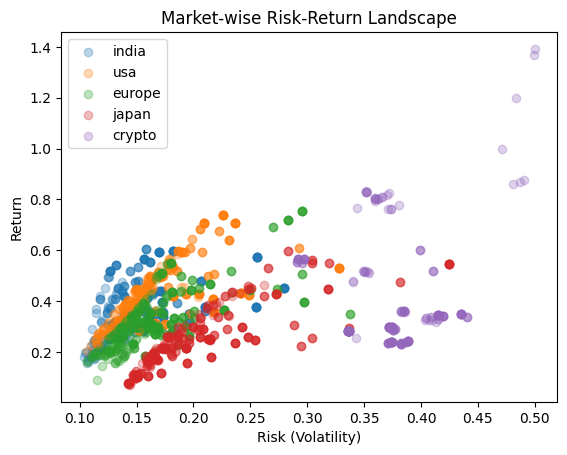

In [47]:
import matplotlib.pyplot as plt

df2 = df[df['volatility'] < 0.5].copy()

for region in df2['market'].unique():
    sub = df2[df2['market'] == region]
    plt.scatter(sub['volatility'], sub['expected_return'], alpha=0.3, label=region)

plt.xlabel('Risk (Volatility)')
plt.ylabel('Return')
plt.title('Market-wise Risk-Return Landscape')
plt.legend()
plt.show()

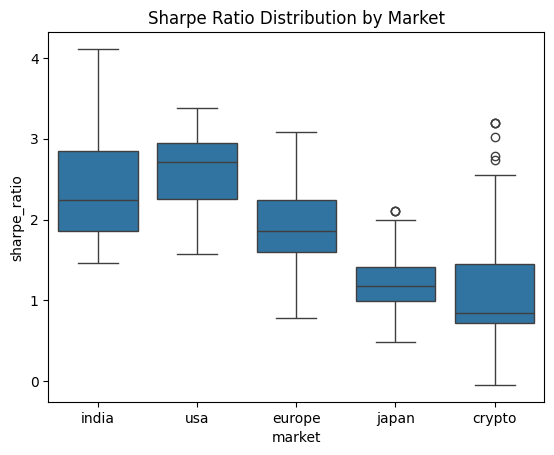

In [48]:
import seaborn as sns

sns.boxplot(x='market', y='sharpe_ratio', data=df)
plt.title('Sharpe Ratio Distribution by Market')
plt.show()

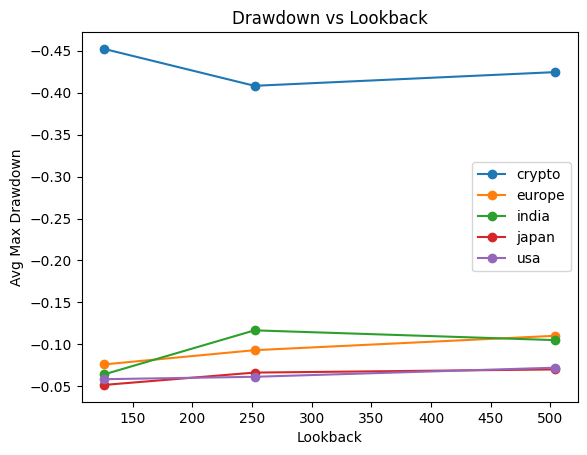

In [49]:
group = df.groupby(['market','lookback'])['max_drawdown'].mean().reset_index()

for region in group['market'].unique():
    sub = group[group['market'] == region]
    plt.plot(sub['lookback'], sub['max_drawdown'], marker='o', label=region)

plt.xlabel('Lookback')
plt.ylabel('Avg Max Drawdown')
plt.title('Drawdown vs Lookback')
plt.legend()
plt.gca().invert_yaxis()
plt.show()

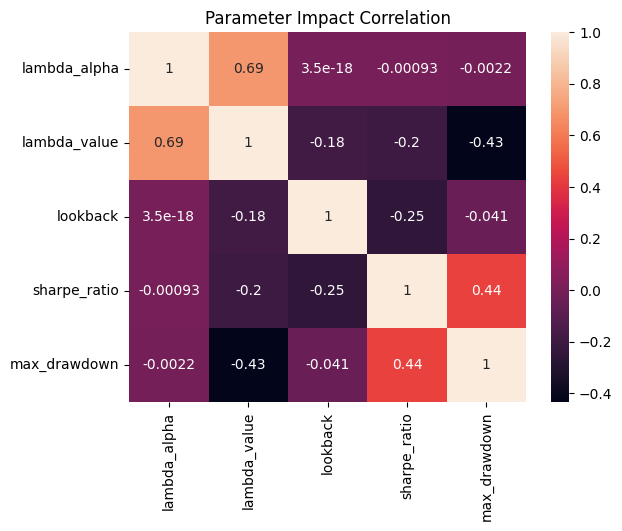

In [50]:
import seaborn as sns

corr = df[['lambda_alpha','lambda_value','lookback','sharpe_ratio','max_drawdown']].corr()

sns.heatmap(corr, annot=True)
plt.title('Parameter Impact Correlation')
plt.show()

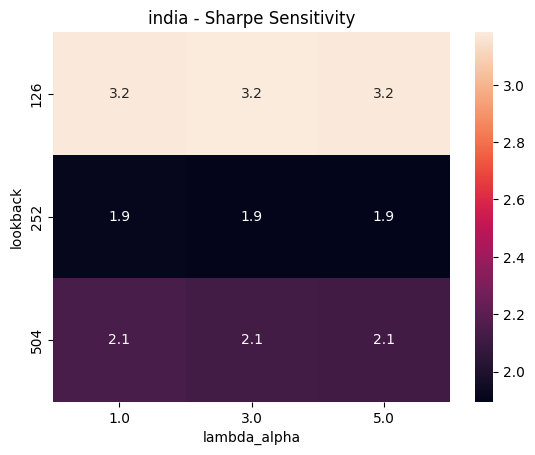

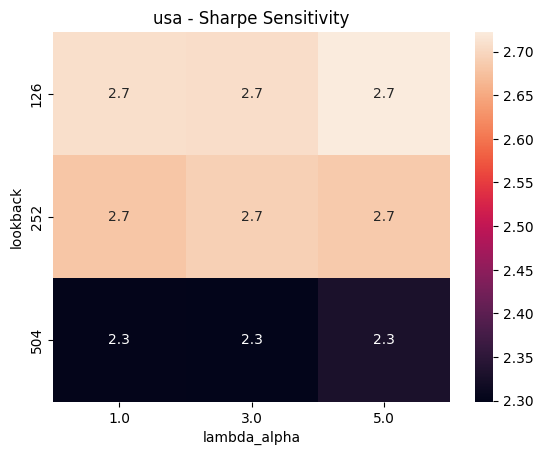

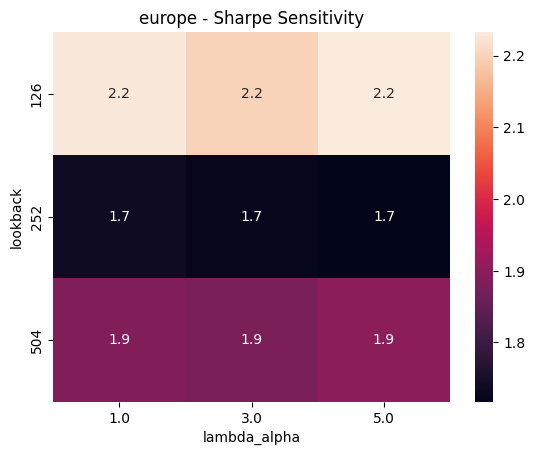

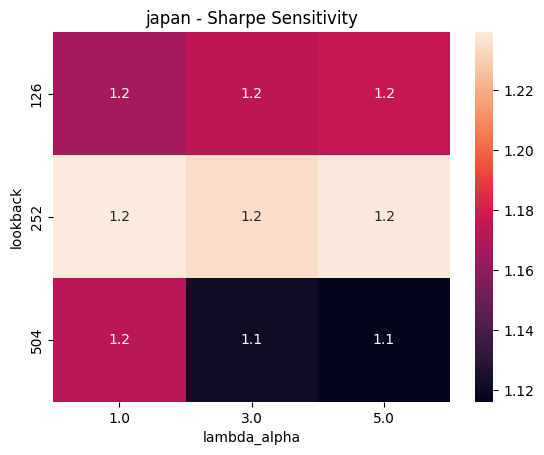

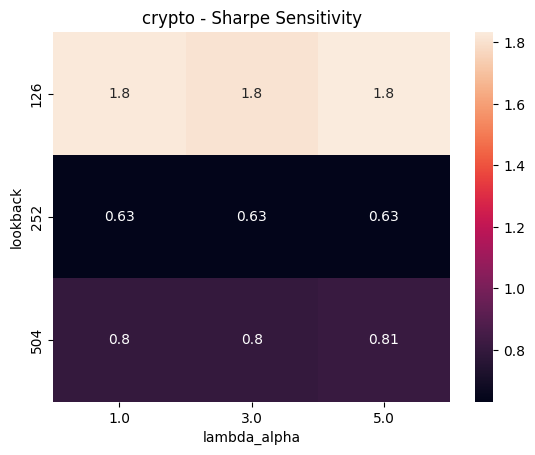

In [51]:
for region in df['market'].unique():
    sub = df[df['market'] == region]
    pivot = sub.pivot_table(values='sharpe_ratio', index='lookback', columns='lambda_alpha')

    plt.figure()
    sns.heatmap(pivot, annot=True)
    plt.title(f'{region} - Sharpe Sensitivity')
    plt.show()

In [52]:
best = df.loc[df.groupby('market')['sharpe_ratio'].idxmax()]
best[['market','lambda_alpha','lambda_value','lookback','sharpe_ratio']]

,market,lambda_alpha,lambda_value,lookback,sharpe_ratio
1950,crypto,5.0,3.342737,126,3.198823
1143,europe,1.0,0.367746,126,3.086965
336,india,3.0,0.777521,126,4.111333
1539,japan,1.0,0.341659,126,2.104304
648,usa,1.0,0.328412,126,3.375765


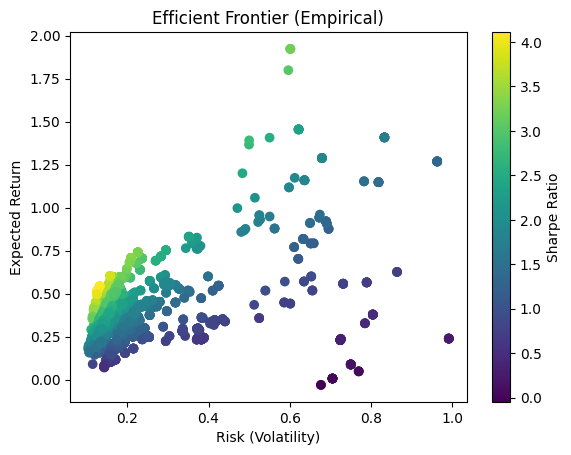

In [53]:
plt.scatter(df['volatility'], df['expected_return'], c=df['sharpe_ratio'])
plt.colorbar(label='Sharpe Ratio')
plt.xlabel('Risk (Volatility)')
plt.ylabel('Expected Return')
plt.title('Efficient Frontier (Empirical)')
plt.show()

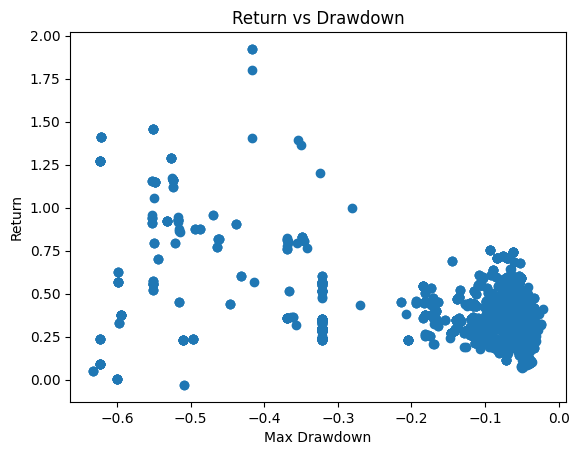

In [54]:
plt.scatter(df['max_drawdown'], df['expected_return'])
plt.xlabel('Max Drawdown')
plt.ylabel('Return')
plt.title('Return vs Drawdown')
plt.show()

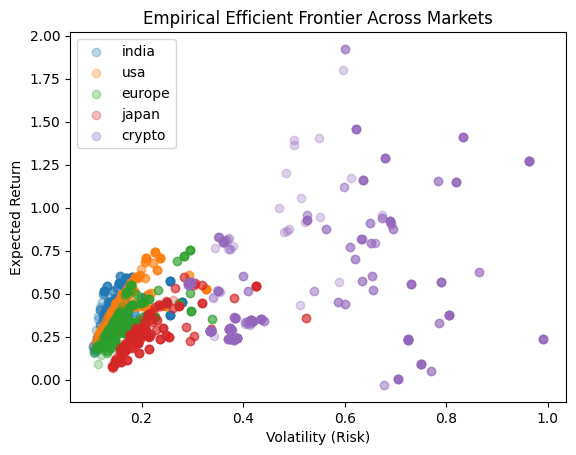

In [55]:
import matplotlib.pyplot as plt

for region in df['market'].unique():
    sub = df[df['market'] == region]
    plt.scatter(sub['volatility'], sub['expected_return'], alpha=0.3, label=region)

plt.xlabel('Volatility (Risk)')
plt.ylabel('Expected Return')
plt.title('Empirical Efficient Frontier Across Markets')
plt.legend()
plt.show()

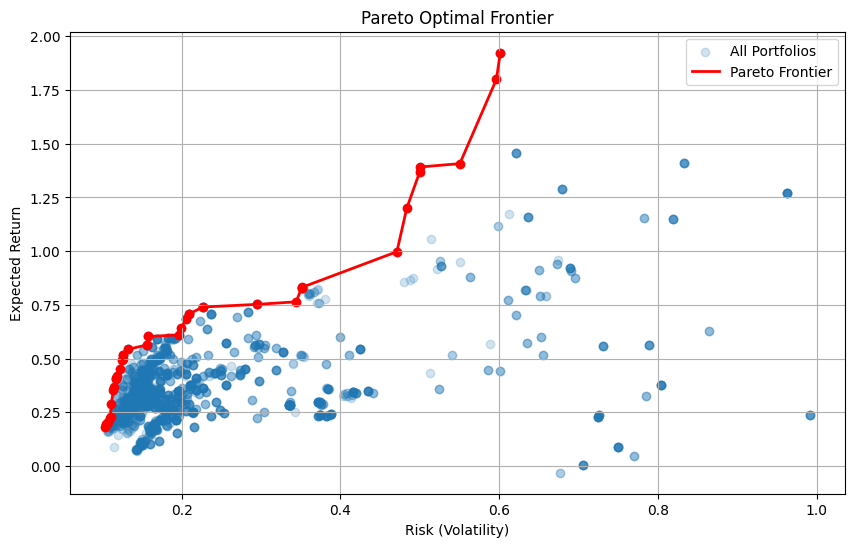

In [62]:
import pandas as pd
import matplotlib.pyplot as plt

def pareto_front(df):
    # Sort by volatility (low → high), return (high → low)
    df_sorted = df.sort_values(['volatility', 'expected_return'], 
                               ascending=[True, False])

    pareto = []
    max_return = -float('inf')

    for _, row in df_sorted.iterrows():
        if row['expected_return'] > max_return:
            pareto.append(row)
            max_return = row['expected_return']

    return pd.DataFrame(pareto)


def plot_pareto(df):
    pf = pareto_front(df)

    # Sort frontier for smooth curve
    pf = pf.sort_values('volatility')

    plt.figure(figsize=(10, 6))

    # All portfolios
    plt.scatter(df['volatility'], df['expected_return'], 
                alpha=0.2, label='All Portfolios')

    # Pareto frontier
    plt.plot(pf['volatility'], pf['expected_return'], 
             color='red', linewidth=2, label='Pareto Frontier')

    # Highlight frontier points
    plt.scatter(pf['volatility'], pf['expected_return'], 
                color='red')

    plt.xlabel('Risk (Volatility)')
    plt.ylabel('Expected Return')
    plt.title('Pareto Optimal Frontier')
    plt.legend()
    plt.grid(True)

    plt.show()

plot_pareto(df)

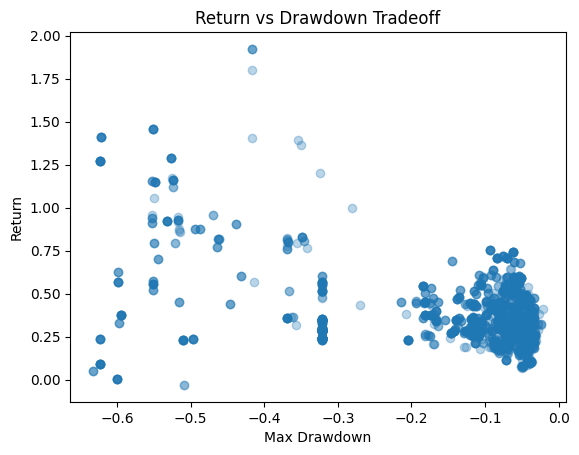

In [57]:
plt.scatter(df['max_drawdown'], df['expected_return'], alpha=0.3)
plt.xlabel('Max Drawdown')
plt.ylabel('Return')
plt.title('Return vs Drawdown Tradeoff')
plt.show()

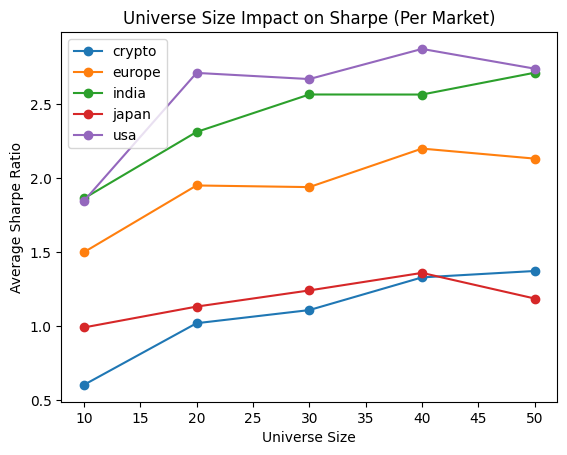

In [63]:
import matplotlib.pyplot as plt

group = df.groupby(['market','universe_size'])['sharpe_ratio'].mean().reset_index()

for region in group['market'].unique():
    sub = group[group['market'] == region]
    sub = sub.sort_values('universe_size')
    plt.plot(sub['universe_size'], sub['sharpe_ratio'], marker='o', label=region)

plt.xlabel('Universe Size')
plt.ylabel('Average Sharpe Ratio')
plt.title('Universe Size Impact on Sharpe (Per Market)')
plt.legend()
plt.show()

In [1]:
'''

group = df.groupby(['market','universe_size'])['sharpe_ratio'].agg(['mean','std']).reset_index()

for region in group['market'].unique():
    sub = group[group['market'] == region].sort_values('universe_size')
    
    plt.plot(sub['universe_size'], sub['mean'], marker='o', label=region)
    plt.fill_between(
        sub['universe_size'],
        sub['mean'] - sub['std'],
        sub['mean'] + sub['std'],
        alpha=0.2
    )

plt.xlabel('Universe Size')
plt.ylabel('Sharpe Ratio')
plt.title('Universe Size vs Sharpe with Variability')
plt.legend()
plt.show()
'''

"\n\ngroup = df.groupby(['market','universe_size'])['sharpe_ratio'].agg(['mean','std']).reset_index()\n\nfor region in group['market'].unique():\n    sub = group[group['market'] == region].sort_values('universe_size')\n\n    plt.plot(sub['universe_size'], sub['mean'], marker='o', label=region)\n    plt.fill_between(\n        sub['universe_size'],\n        sub['mean'] - sub['std'],\n        sub['mean'] + sub['std'],\n        alpha=0.2\n    )\n\nplt.xlabel('Universe Size')\nplt.ylabel('Sharpe Ratio')\nplt.title('Universe Size vs Sharpe with Variability')\nplt.legend()\nplt.show()\n"

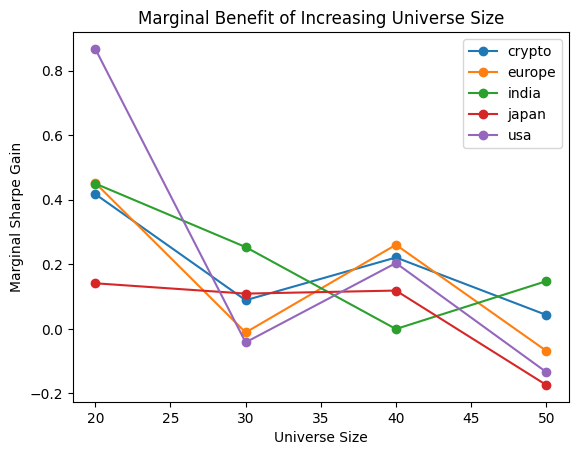

In [60]:
group = df.groupby(['market','universe_size'])['sharpe_ratio'].mean().reset_index()

group['delta'] = group.groupby('market')['sharpe_ratio'].diff()

for region in group['market'].unique():
    sub = group[group['market']==region]
    plt.plot(sub['universe_size'], sub['delta'], marker='o', label=region)

plt.xlabel('Universe Size')
plt.ylabel('Marginal Sharpe Gain')
plt.title('Marginal Benefit of Increasing Universe Size')
plt.legend()
plt.show()